# 05 — Segment-wise multi-output Random Forest baseline

## Problem
Missing sensor observations must not become fake zero-speed targets. Independent segment models also provide a clear baseline before adding real road-link propagation.

## Solution
Train one small multi-output Random Forest per METR-LA sensor segment. Each model predicts 5, 15, 30, and 60-minute speeds from that segment's own observed speed lags and cyclic time features. Training only uses timestamps where all four target speeds for that segment are observed; test metrics mask every unobserved target. The split is chronological: 70% train, 10% reserved validation, 20% test.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
FIG = ROOT / 'results' / 'figures'
METRICS = ROOT / 'results' / 'metrics'
PREDICTIONS = ROOT / 'results' / 'predictions'
for folder in [FIG, METRICS, PREDICTIONS]:
    folder.mkdir(parents=True, exist_ok=True)

traffic = pd.read_csv(DATA / 'METR-LA.csv', index_col=0, parse_dates=True)
traffic.index.name = 'timestamp'
traffic.columns = traffic.columns.astype(str)
sensor_ids = traffic.columns.tolist()
traffic = traffic.apply(pd.to_numeric, errors='coerce').astype('float32')
assert traffic.index.is_monotonic_increasing and not traffic.index.has_duplicates
assert traffic.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=5)).all()

observed = traffic.where(traffic > 0).to_numpy(dtype=np.float32)
train_end = int(len(traffic) * .70)
validation_end = int(len(traffic) * .80)
speed_inputs = pd.DataFrame(observed).ffill().to_numpy(dtype=np.float32)
train_medians = np.nanmedian(observed[:train_end], axis=0)
assert np.isfinite(train_medians).all()
speed_inputs = np.where(np.isfinite(speed_inputs), speed_inputs, train_medians[None, :])
minute = (traffic.index.hour * 60 + traffic.index.minute).to_numpy()
weekday = traffic.index.dayofweek.to_numpy()
horizons = {5: 1, 15: 3, 30: 6, 60: 12}
steps = np.array(list(horizons.values()), dtype=np.int32)
origins = np.arange(5, len(traffic) - steps.max(), dtype=np.int32)
test_origins = origins[origins >= validation_end]
time_features = np.column_stack([
    np.sin(2 * np.pi * minute / 1440), np.cos(2 * np.pi * minute / 1440),
    np.sin(2 * np.pi * weekday / 7), np.cos(2 * np.pi * weekday / 7)
]).astype(np.float32)
print(f'METR-LA: {len(traffic):,} timestamps x {len(sensor_ids)} segments')
print(f'Chronological train/validation/test boundaries: {train_end:,} / {validation_end:,} / {len(traffic):,}')
print(f'Observed targets: {np.isfinite(observed).mean():.1%}; zero readings are masked, not training labels.')

METR-LA: 34,272 timestamps x 207 segments
Chronological train/validation/test boundaries: 23,990 / 27,417 / 34,272
Observed targets: 91.9%; zero readings are masked, not training labels.


In [2]:
score_sums = {minutes: {'abs': 0.0, 'square': 0.0, 'ape': 0.0, 'count': 0} for minutes in horizons}
period_sums = {minutes: {period: {name: {'abs': 0.0, 'square': 0.0, 'ape': 0.0, 'count': 0} for name in ['Persistence', 'Random Forest']} for period in ['Peak', 'Off-peak']} for minutes in horizons}
sample_sensor = len(sensor_ids) // 2
sample_predictions = {}
training_counts = []
for sensor_idx, sensor_id in enumerate(sensor_ids):
    X = np.column_stack([
        speed_inputs[origins, sensor_idx],
        speed_inputs[origins - 1, sensor_idx],
        speed_inputs[origins - 2, sensor_idx],
        speed_inputs[origins - 5, sensor_idx],
        time_features[origins]
    ]).astype(np.float32, copy=False)
    target_idx = origins[:, None] + steps[None, :]
    targets = observed[target_idx, sensor_idx]
    train_mask = (target_idx[:, -1] < train_end) & np.isfinite(targets).all(axis=1)
    train_rows = np.flatnonzero(train_mask)
    if len(train_rows) > 2000:
        train_rows = np.sort(np.random.default_rng(42 + sensor_idx).choice(train_rows, 2000, replace=False))
    assert len(train_rows) > 0, f'No complete training target rows for sensor {sensor_id}.'
    model = RandomForestRegressor(
        n_estimators=10, max_depth=10, min_samples_leaf=8,
        max_features=1.0, n_jobs=1, random_state=42
    )
    model.fit(X[train_rows], targets[train_rows])
    test_rows = np.flatnonzero(origins >= validation_end)
    prediction = model.predict(X[test_rows]).astype(np.float32)
    actual = observed[origins[test_rows, None] + steps[None, :], sensor_idx]
    persistence = speed_inputs[origins[test_rows], sensor_idx]
    target_times = origins[test_rows, None] + steps[None, :]
    target_hours = traffic.index.hour.to_numpy()[target_times]
    target_weekdays = traffic.index.dayofweek.to_numpy()[target_times]
    peak_mask = (target_weekdays < 5) & (((target_hours >= 7) & (target_hours < 10)) | ((target_hours >= 16) & (target_hours < 19)))
    for h_idx, minutes in enumerate(horizons):
        valid_all = np.isfinite(actual[:, h_idx])
        for name, estimate in [('Persistence', persistence), ('Random Forest', prediction[:, h_idx])]:
            error = actual[valid_all, h_idx] - estimate[valid_all]
            score = score_sums[minutes].setdefault(name, {'abs': 0.0, 'square': 0.0, 'ape': 0.0, 'count': 0})
            score['abs'] += np.abs(error).sum()
            score['square'] += np.square(error).sum()
            score['ape'] += (np.abs(error) / actual[valid_all, h_idx]).sum()
            score['count'] += int(valid_all.sum())
            for period, period_valid in [('Peak', peak_mask[:, h_idx]), ('Off-peak', ~peak_mask[:, h_idx])]:
                valid = valid_all & period_valid
                error = actual[valid, h_idx] - estimate[valid]
                period_score = period_sums[minutes][period][name]
                period_score['abs'] += np.abs(error).sum()
                period_score['square'] += np.square(error).sum()
                period_score['ape'] += (np.abs(error) / actual[valid, h_idx]).sum()
                period_score['count'] += int(valid.sum())
    training_counts.append(len(train_rows))
    if sensor_idx == sample_sensor:
        sample_predictions = {
            minutes: pd.DataFrame({
                'timestamp': traffic.index[origins[test_rows] + step],
                'actual_speed': actual[:, h_idx],
                'predicted_speed': prediction[:, h_idx]
            })
            for h_idx, (minutes, step) in enumerate(horizons.items())
        }
    if (sensor_idx + 1) % 50 == 0:
        print(f'Trained {sensor_idx + 1}/{len(sensor_ids)} segments')
print(f'Training timestamps per segment: median {np.median(training_counts):.0f}, range {min(training_counts)}–{max(training_counts)}')
period_scores = []
for minutes in horizons:
    for period in ['Peak', 'Off-peak']:
        for name in ['Persistence', 'Random Forest']:
            values = period_sums[minutes][period][name]
            period_scores.append({'dataset': 'METR-LA', 'model': name, 'period': period, 'horizon_minutes': minutes,
                                  'MAE': values['abs'] / values['count'],
                                  'MAPE_percent': values['ape'] / values['count'] * 100,
                                  'RMSE': np.sqrt(values['square'] / values['count']),
                                  'valid_test_values': values['count']})
pd.DataFrame(period_scores).to_csv(METRICS / 'metr_la_baseline_period_metrics.csv', index=False)
print('Saved peak/off-peak baseline metrics.')

Trained 50/207 segments


Trained 100/207 segments


Trained 150/207 segments


Trained 200/207 segments


Training timestamps per segment: median 2000, range 2000–2000
Saved peak/off-peak baseline metrics.


In [3]:
scores = []
for minutes in horizons:
    for model_name in ['Persistence', 'Random Forest']:
        values = score_sums[minutes][model_name]
        scores.append({
            'dataset': 'METR-LA', 'model': model_name, 'horizon_minutes': minutes,
            'MAE': values['abs'] / values['count'],
            'MAPE_percent': values['ape'] / values['count'] * 100,
            'RMSE': np.sqrt(values['square'] / values['count']),
            'valid_test_values': values['count'],
            'training_timestamps_median': int(np.median(training_counts)) if model_name == 'Random Forest' else np.nan
        })
metrics = pd.DataFrame(scores)
metrics.to_csv(METRICS / 'metr_la_baseline_metrics.csv', index=False)
display(metrics.round(3))
period_metrics = pd.read_csv(METRICS / 'metr_la_baseline_period_metrics.csv')
display(period_metrics.round(3))

,dataset,model,horizon_minutes,MAE,MAPE_percent,RMSE,valid_test_values,training_timestamps_median
0,METR-LA,Persistence,5,2.814,6.489,4.627,1244846,NaN
1,METR-LA,Random Forest,5,2.519,6.327,4.281,1244846,2000.0
2,METR-LA,Persistence,15,3.499,8.612,6.418,1244834,NaN
3,METR-LA,Random Forest,15,3.119,8.431,5.702,1244834,2000.0
4,METR-LA,Persistence,30,4.207,10.858,8.052,1244816,NaN
5,METR-LA,Random Forest,30,3.635,10.401,6.706,1244816,2000.0
6,METR-LA,Persistence,60,5.381,14.535,10.345,1244780,NaN
7,METR-LA,Random Forest,60,4.192,12.623,7.657,1244780,2000.0


,dataset,model,period,horizon_minutes,MAE,MAPE_percent,RMSE,valid_test_values
0,METR-LA,Persistence,Peak,5,3.287,10.044,5.479,250523
1,METR-LA,Random Forest,Peak,5,3.189,10.712,5.381,250523
2,METR-LA,Persistence,Off-peak,5,2.695,5.593,4.386,994323
3,METR-LA,Random Forest,Off-peak,5,2.350,5.222,3.955,994323
4,METR-LA,Persistence,Peak,15,4.565,14.384,8.223,250523
5,METR-LA,Random Forest,Peak,15,4.341,15.101,7.580,250523
6,METR-LA,Persistence,Off-peak,15,3.230,7.157,5.877,994311
7,METR-LA,Random Forest,Off-peak,15,2.812,6.750,5.121,994311
8,METR-LA,Persistence,Peak,30,5.831,19.080,10.552,250523
9,METR-LA,Random Forest,Peak,30,5.324,19.281,9.105,250523


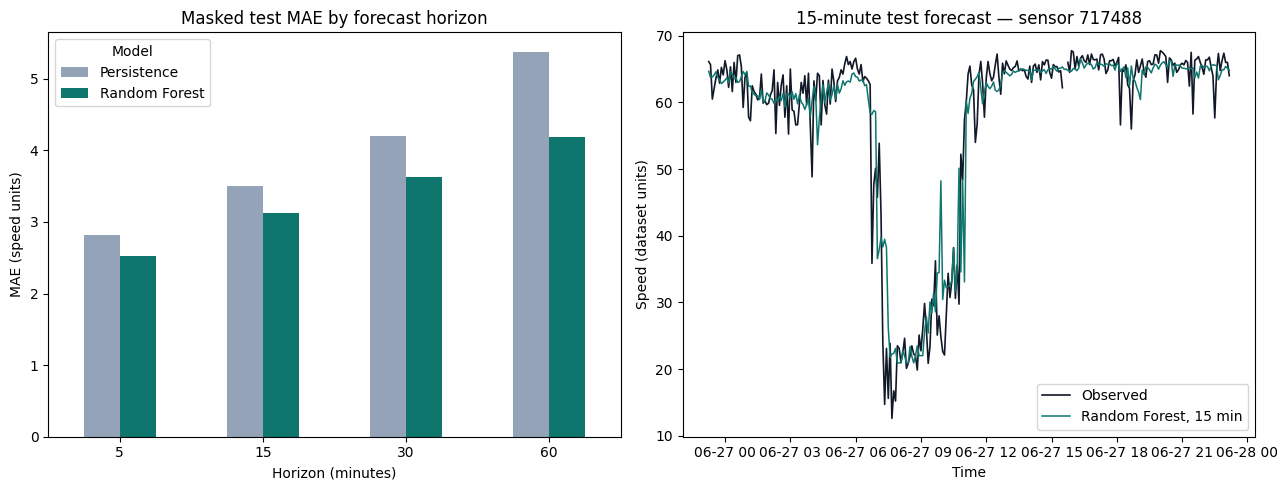

Saved masked-target RF metrics, sample predictions, and figure.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mae = metrics.pivot(index='horizon_minutes', columns='model', values='MAE')
mae.plot(kind='bar', ax=axes[0], color=['#94a3b8', '#0f766e'])
axes[0].set(title='Masked test MAE by forecast horizon', xlabel='Horizon (minutes)', ylabel='MAE (speed units)')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Model')
times = sample_predictions[15]['timestamp']
recent = sample_predictions[15].tail(288)
axes[1].plot(recent['timestamp'], recent['actual_speed'], label='Observed', color='#111827', lw=1.2)
axes[1].plot(recent['timestamp'], recent['predicted_speed'], label='Random Forest, 15 min', color='#0f766e', lw=1.1)
axes[1].set(title=f'15-minute test forecast — sensor {sensor_ids[sample_sensor]}', xlabel='Time', ylabel='Speed (dataset units)')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / '20_metr_la_random_forest_baseline.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
sample_predictions[15].to_csv(PREDICTIONS / 'metr_la_random_forest_sample_sensor.csv', index=False)
print('Saved masked-target RF metrics, sample predictions, and figure.')